In [11]:
# constructing the figure for HST/Webb
# nircam time

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "text.latex.preamble": r"""
# \usepackage[T1]{fontenc}
# \usepackage{newtxtext,newtxmath}
# """,

#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
#     "legend.fontsize": 10,
#     "figure.titlesize": 10,
# })

# plt.rcParams["figure.dpi"] = 300
# # fig_width = 379.41753 / 72.27 # = 5.25
# fig_width = 5.25


# new style
preamble = r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
"""

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "figure.titlesize": 7,

    "figure.dpi": 300,
    "savefig.bbox": None,

        # Settings for PDF export through LaTeX:
    "pgf.texsystem": "pdflatex",
    "pgf.rcfonts": False,
    "pgf.preamble": preamble,
})

fig_width = 170 / 25.4  # 6.693 inches

/Library/TeX/texbin/latex


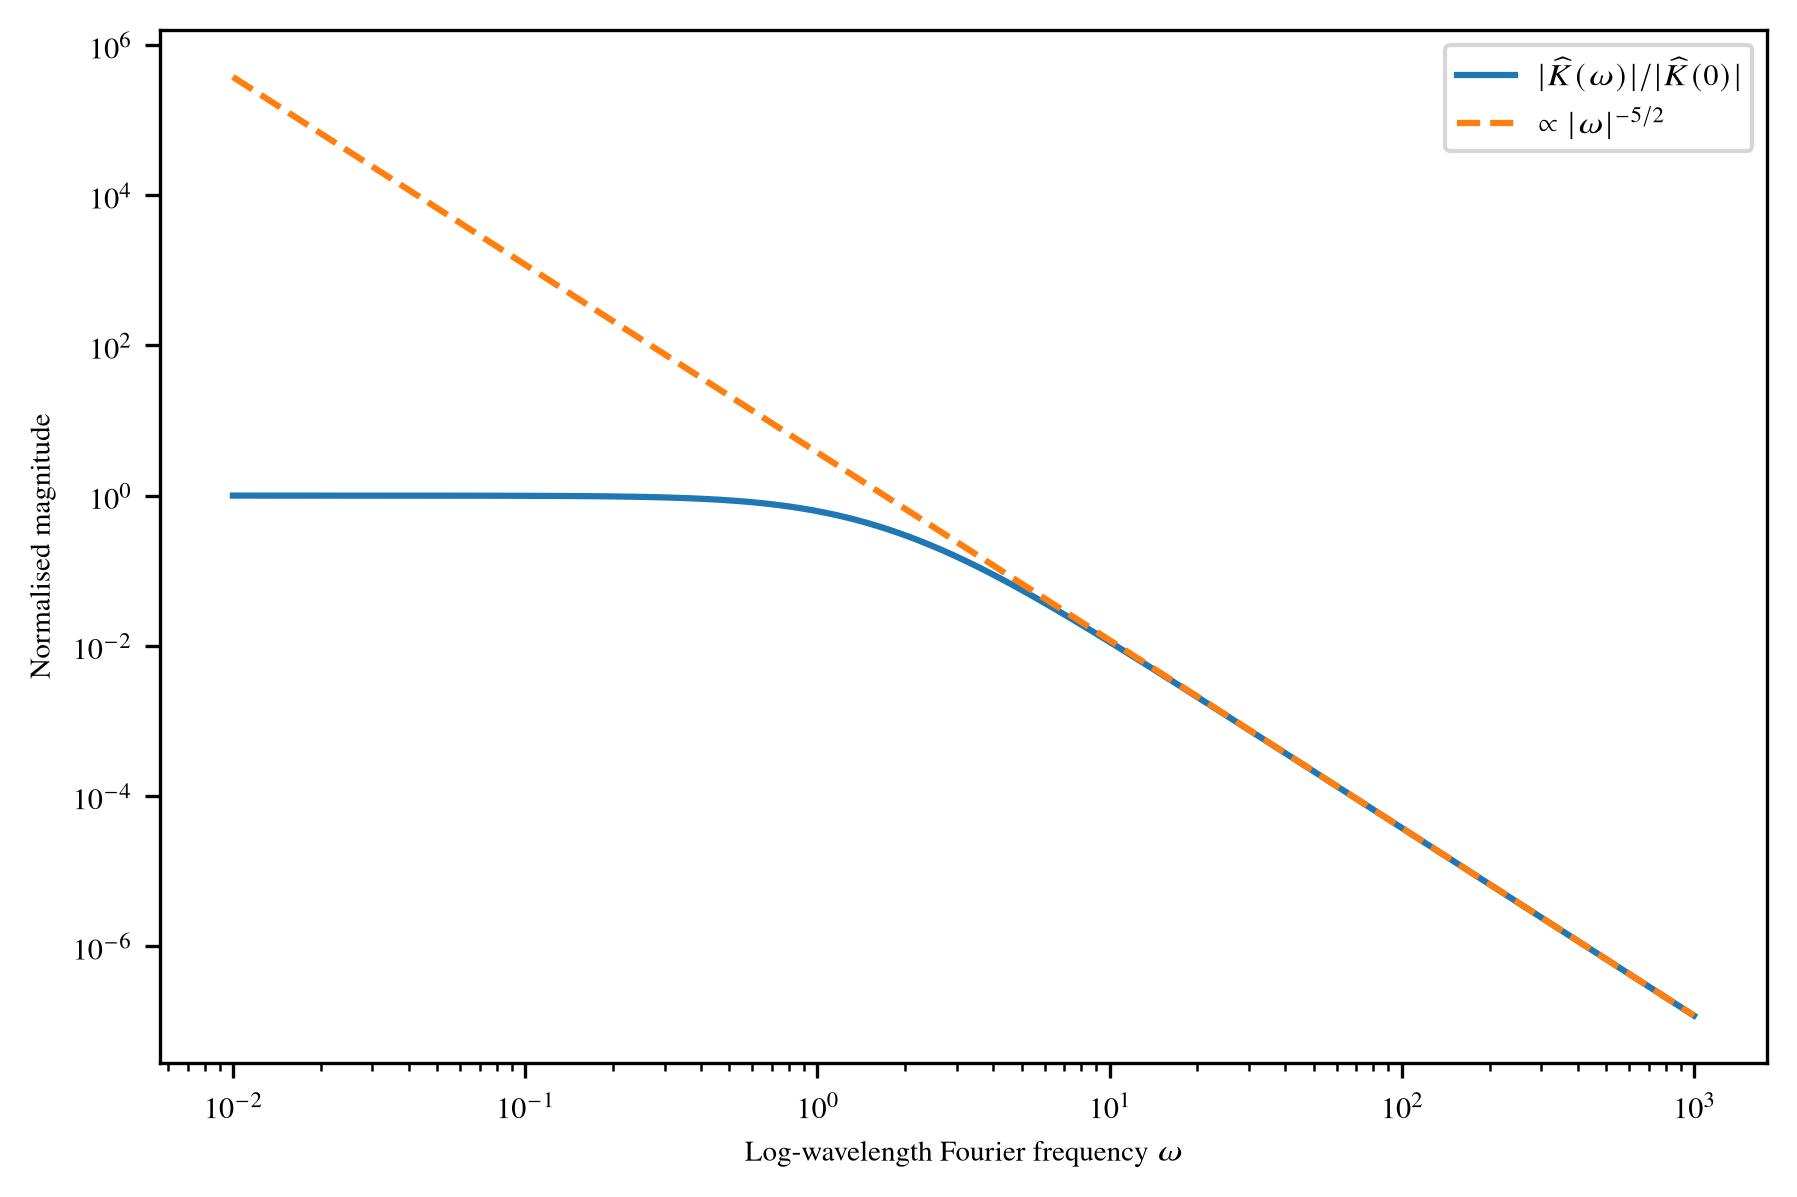

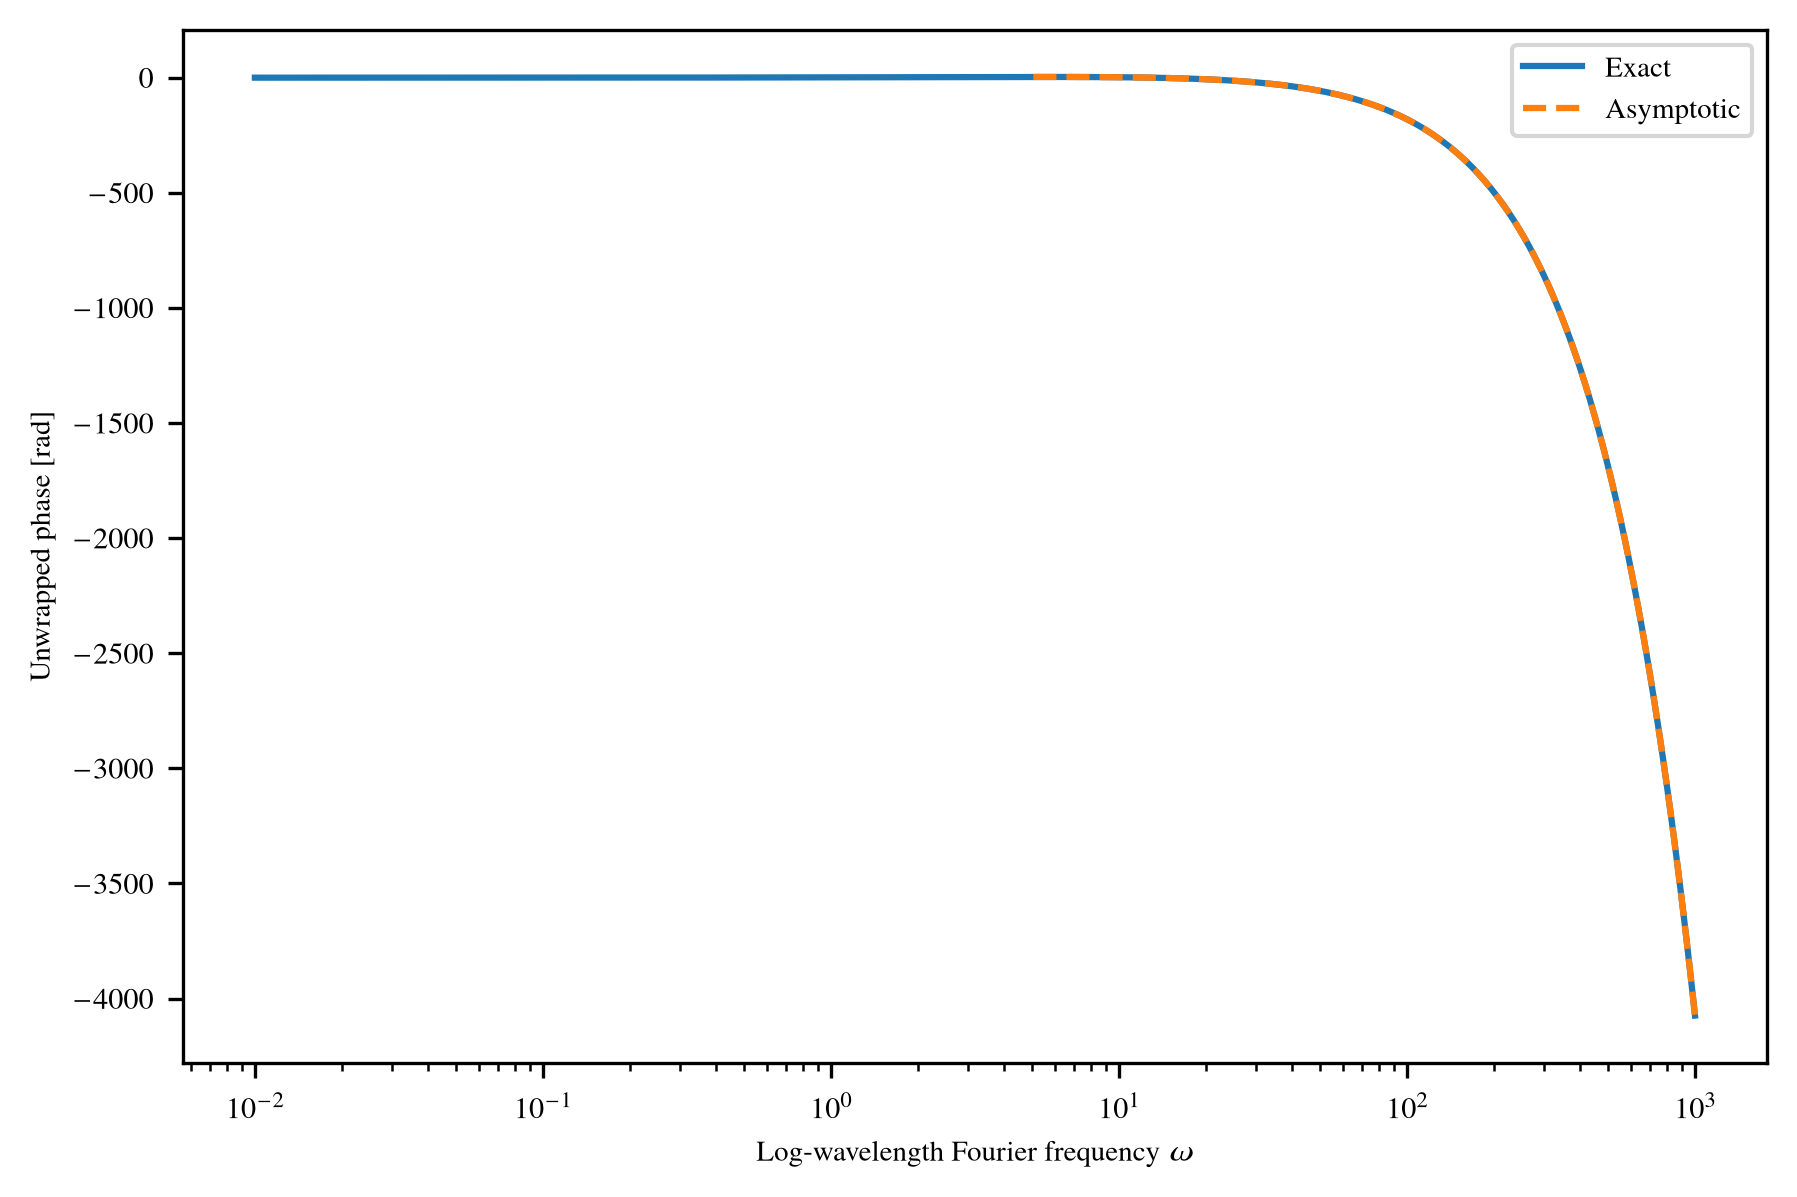

In [12]:
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

mp.mp.dps = 50

# Numerical value in your chosen nondimensionalisation.
D = 1.0


# ------------------------------------------------------------
# Exact magnitude
# ------------------------------------------------------------

def K_abs(omega, D=1.0):
    w = abs(mp.mpf(omega))

    # continuous omega -> 0 limit
    if w == 0:
        return 4 * D / (3 * mp.pi)

    return (
        2 * mp.sqrt(2) * D / mp.sqrt(mp.pi)
        * mp.sqrt(w * mp.coth(mp.pi * w / 2))
        / ((w**2 + 1) * mp.sqrt(w**2 + 9))
    )


def K_abs_asymptotic(omega, D=1.0):
    w = abs(mp.mpf(omega))

    return (
        2 * mp.sqrt(2) * D / mp.sqrt(mp.pi)
        * w**(-mp.mpf("2.5"))
    )


# ------------------------------------------------------------
# Exact complex log Khat
#
# Using loggamma avoids catastrophic underflow at large omega.
# Im(log_Khat) gives a naturally unwrapped phase.
# ------------------------------------------------------------

def log_Khat(omega, D=1.0):
    w = mp.mpf(omega)
    t = w / 2

    return (
        mp.log(D)
        + 1j * w * mp.log(mp.pi * D)
        - mp.log(2)
        - 0.5 * mp.log(mp.pi)
        + mp.loggamma(1 + 1j*t)
        + mp.loggamma(mp.mpf("0.5") - 1j*t)
        - mp.loggamma(mp.mpf("1.5") + 1j*t)
        - mp.loggamma(mp.mpf("2.5") + 1j*t)
    )


def K_phase(omega, D=1.0):
    return mp.im(log_Khat(omega, D))


def K_phase_asymptotic(omega, D=1.0):
    w = mp.mpf(omega)

    return (
        w * (1 + mp.log(2 * mp.pi * D / abs(w)))
        - 5 * mp.pi / 4 * mp.sign(w)
        + 55 / (12 * w)
    )


# ------------------------------------------------------------
# Frequency grid
# ------------------------------------------------------------

omega = np.logspace(-2, 3, 1000)

mag = np.array([
    float(K_abs(w, D)) for w in omega
])

mag_asym = np.array([
    float(K_abs_asymptotic(w, D)) for w in omega
])

phase = np.array([
    float(K_phase(w, D)) for w in omega
])

phase_asym = np.array([
    float(K_phase_asymptotic(w, D)) for w in omega
])


# ------------------------------------------------------------
# Normalise magnitude to DC response
# ------------------------------------------------------------

K0 = 4 * D / (3 * np.pi)

mag /= K0
mag_asym /= K0


# ------------------------------------------------------------
# Magnitude plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 4))

ax.loglog(
    omega,
    mag,
    label=r'$|\widehat{K}(\omega)|/|\widehat{K}(0)|$'
)

ax.loglog(
    omega,
    mag_asym,
    '--',
    label=r'$\propto |\omega|^{-5/2}$'
)

ax.set_xlabel(r'Log-wavelength Fourier frequency $\omega$')
ax.set_ylabel('Normalised magnitude')
ax.legend()

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# Unwrapped phase
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 4))

ax.semilogx(
    omega,
    phase,
    label='Exact'
)

# asymptotic only becomes useful once omega is moderately large
mask = omega > 5

ax.semilogx(
    omega[mask],
    phase_asym[mask],
    '--',
    label='Asymptotic'
)

ax.set_xlabel(r'Log-wavelength Fourier frequency $\omega$')
ax.set_ylabel(r'Unwrapped phase [rad]')
ax.legend()

fig.tight_layout()
plt.show()

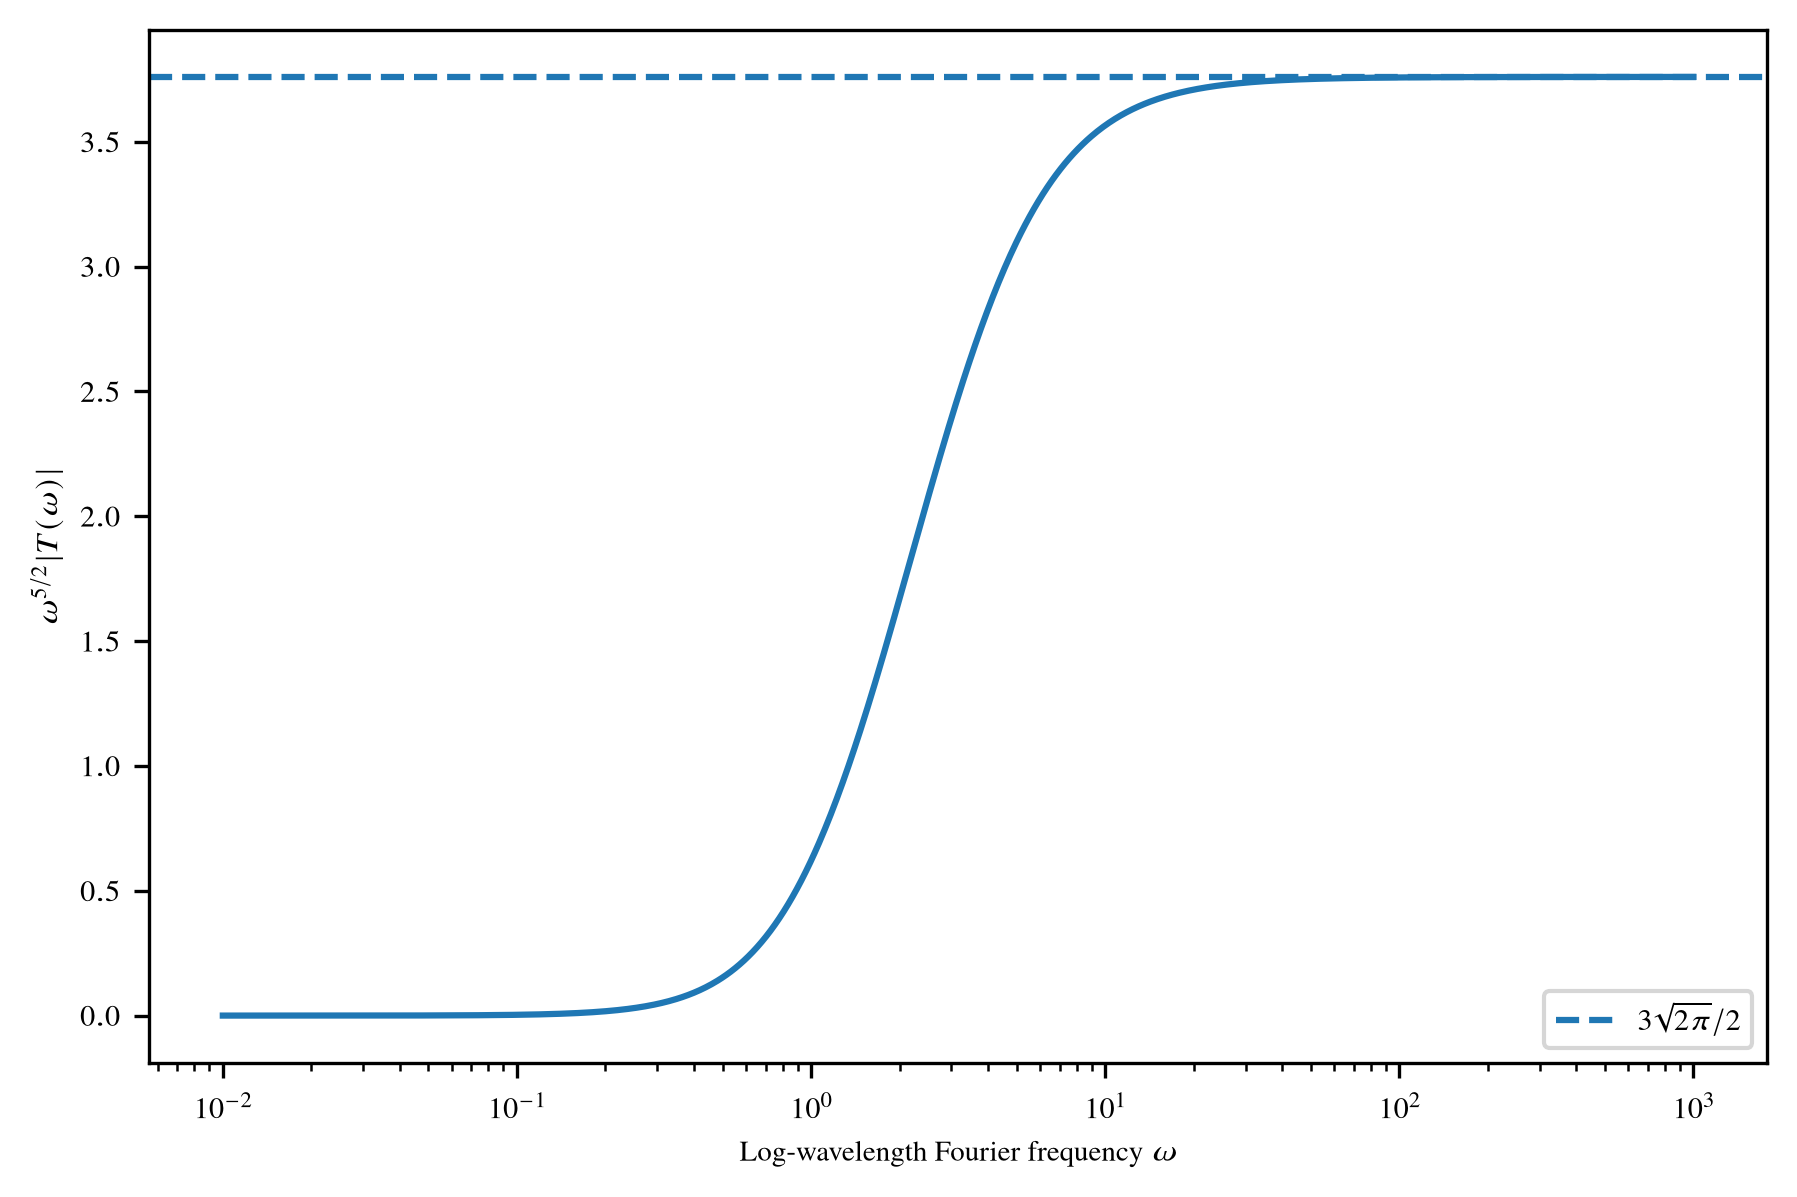

In [13]:
scaled_mag = omega**2.5 * mag

asymptotic_constant = 3 * np.sqrt(2 * np.pi) / 2

fig, ax = plt.subplots(figsize=(6, 4))

ax.semilogx(omega, scaled_mag)

ax.axhline(
    asymptotic_constant,
    linestyle='--',
    label=r'$3\sqrt{2\pi}/2$'
)

ax.set_xlabel(r'Log-wavelength Fourier frequency $\omega$')
ax.set_ylabel(r'$\omega^{5/2}|T(\omega)|$')

ax.legend()
fig.tight_layout()

In [14]:
eta = np.linspace(-8, 6, 3000)
r = np.exp(eta)

x = np.pi * D * r
jinc = np.where(
    x == 0,
    0.5,
    np.array([float(mp.besselj(1, xx) / xx) for xx in x])
)

K_eta = np.pi * D**2 * np.exp(eta) * jinc**2
K_eta /= K_eta.max()

In [15]:
ax.semilogy(eta, K_eta)
ax.set_xlabel(r'Log-radius $\eta$')
ax.set_ylabel(r'$K(\eta)/\max K$')

Text(63.43239321457297, 0.5, '$K(\\eta)/\\max K$')

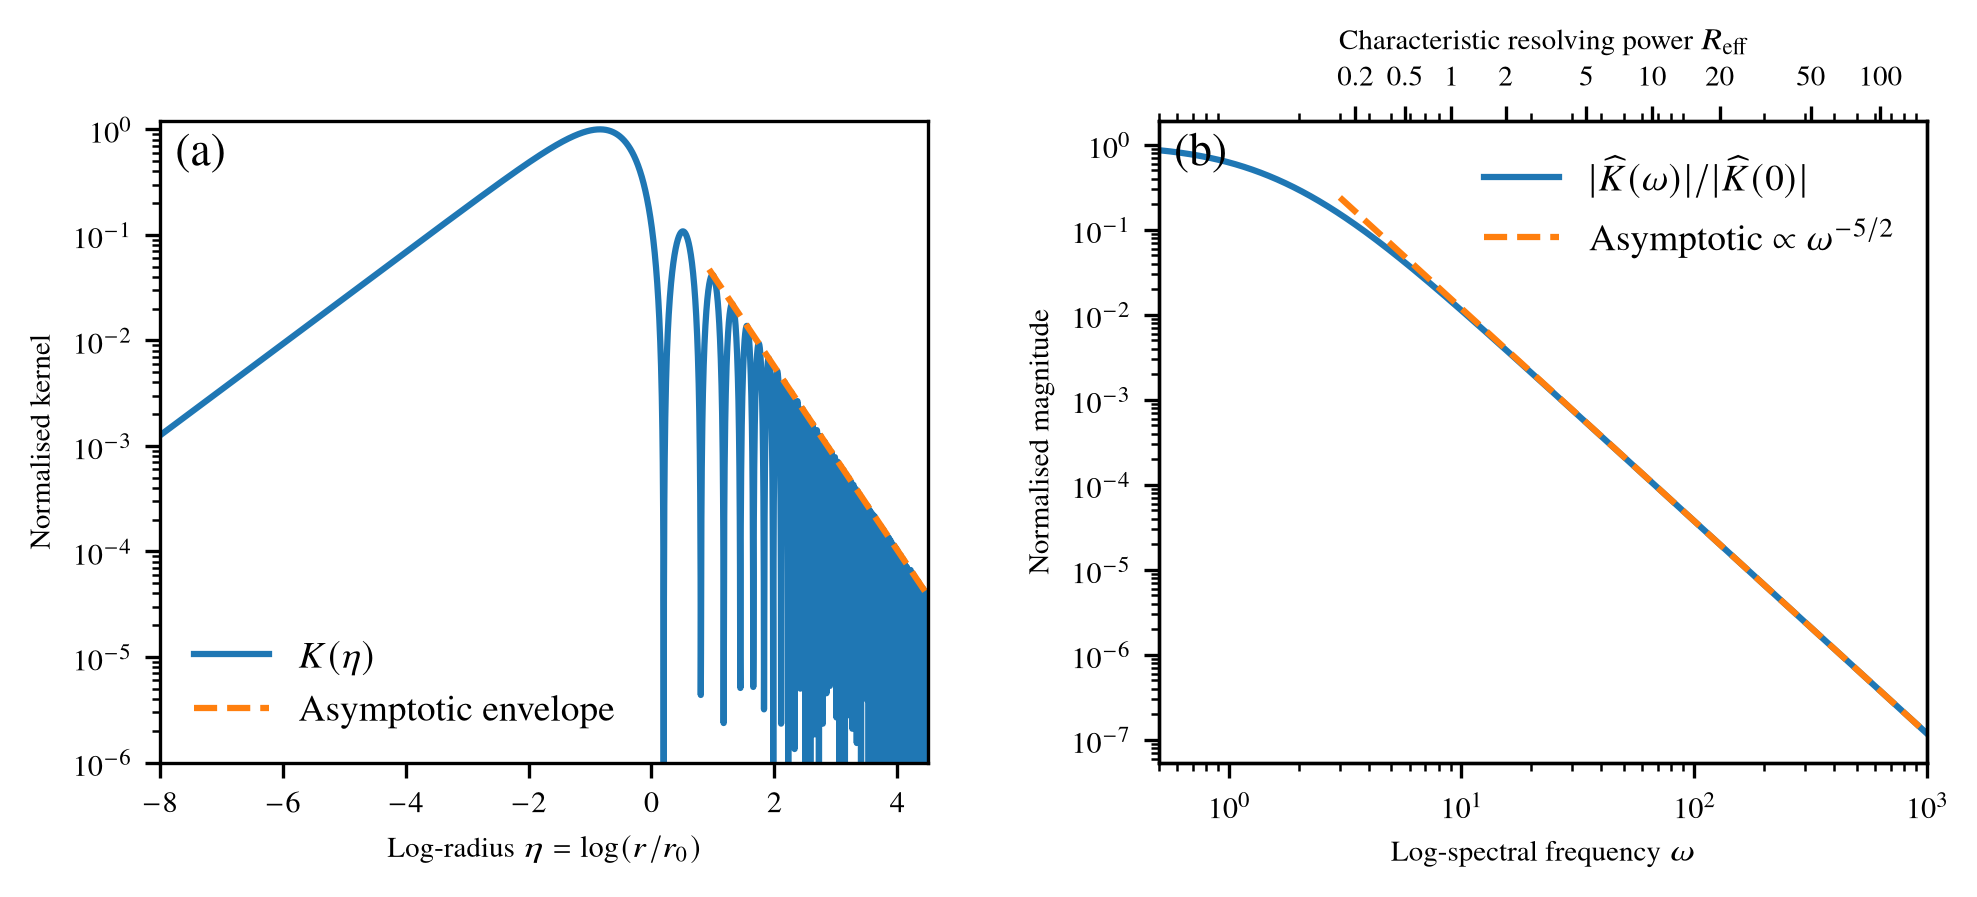

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

# ============================================================
# User controls
# ============================================================

D = 1.0           # use your nondimensionalised D here

eta_min, eta_max = -8.0, 4.5
n_eta = 4000

omega_min, omega_max = 0.5, 1e3
n_omega = 1200

# subplot / whitespace controls
left   = 0.10
right  = 0.98
bottom = 0.15
top    = 0.86
wspace = 0.30

# panel labels
label_fs = 11

# ============================================================
# Helper functions
# ============================================================

def jinc(x):
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x)

    small = np.isclose(x, 0.0)
    out[small] = 0.5
    out[~small] = j1(x[~small]) / x[~small]

    return out


# Real-space spectral convolution kernel:
# K(eta) = exp(eta) g(exp(eta))
# for g(r) = pi D^2 jinc^2(pi D r)
def K_eta(eta, D=1.0):
    eta = np.asarray(eta, dtype=float)
    r = np.exp(eta)
    x = np.pi * D * r
    return np.pi * D**2 * np.exp(eta) * jinc(x)**2


# Large-eta asymptotic envelope:
# K(eta) ~ [2 / (pi^3 D)] exp(-2 eta) cos^2(...)
# If kind="upper", keep cos^2 -> 1
# If kind="mean", use average cos^2 -> 1/2
def K_eta_asymptotic_envelope(eta, D=1.0, kind="upper"):
    eta = np.asarray(eta, dtype=float)

    prefac = 2.0 / (np.pi**3 * D)
    if kind == "mean":
        prefac *= 0.5

    return prefac * np.exp(-2.0 * eta)


# Exact |Khat(omega)| for omega > 0
def Khat_abs(omega, D=1.0):
    omega = np.asarray(omega, dtype=float)

    return (
        2.0 * np.sqrt(2.0) * D / np.sqrt(np.pi)
        * np.sqrt(omega / np.tanh(np.pi * omega / 2.0))
        / ((omega**2 + 1.0) * np.sqrt(omega**2 + 9.0))
    )


# Normalised transfer magnitude |T(omega)| = |Khat(omega)| / |Khat(0)|
def T_abs(omega, D=1.0):
    K0 = 4.0 * D / (3.0 * np.pi)
    return Khat_abs(omega, D) / K0


# Large-omega asymptotic of the normalised transfer magnitude
def T_abs_asymptotic(omega):
    omega = np.asarray(omega, dtype=float)
    return (3.0 * np.sqrt(2.0 * np.pi) / 2.0) * omega**(-2.5)


# Map omega <-> effective resolving power
# Derived from: 2 pi / omega = log(1 + 1/R)
def R_eff_from_omega(omega):
    omega = np.asarray(omega, dtype=float)
    return 1.0 / np.expm1(2.0 * np.pi / omega)

def omega_from_R_eff(R):
    R = np.asarray(R, dtype=float)
    return 2.0 * np.pi / np.log1p(1.0 / R)


# ============================================================
# Compute curves
# ============================================================

eta = np.linspace(eta_min, eta_max, n_eta)
K = K_eta(eta, D=D)
K_max = K.max()
K_norm = K / K_max

# choose whether you want "upper" or "mean" envelope
K_env = K_eta_asymptotic_envelope(eta, D=D, kind="upper") / K_max

# only show envelope where asymptotic is actually sensible
x_eta = np.pi * D * np.exp(eta)
mask_env = x_eta > 8.0

omega = np.logspace(np.log10(omega_min), np.log10(omega_max), n_omega)
T = T_abs(omega, D=D)
T_asym = T_abs_asymptotic(omega)

# only show Fourier asymptotic once omega is moderately large
mask_asym = omega > 3.0


# ============================================================
# Plot
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(fig_width, 0.45 * fig_width)
)

fig.subplots_adjust(
    left=left, right=right,
    bottom=bottom, top=top,
    wspace=wspace
)

# ------------------------------------------------------------
# Left panel: real-space kernel
# ------------------------------------------------------------

ax1.semilogy(eta, K_norm, label=r'$K(\eta)$')
ax1.semilogy(
    eta[mask_env], K_env[mask_env], '--',
    label='Asymptotic envelope'
)

ax1.set_xlim(eta_min, eta_max)
ax1.set_ylim(1e-6, 1.2)

ax1.set_xlabel(r'Log-radius $\eta = \log(r/r_0)$')
ax1.set_ylabel(r'Normalised kernel')
ax1.legend(frameon=False, fontsize=9)

ax1.text(
    0.02, 0.98, '(a)',
    transform=ax1.transAxes,
    ha='left', va='top',
    fontsize=label_fs
)

# ------------------------------------------------------------
# Right panel: Fourier-space transfer magnitude
# ------------------------------------------------------------

ax2.loglog(
    omega, T,
    label=r'$|\widehat{K}(\omega)|/|\widehat{K}(0)|$'
)
ax2.loglog(
    omega[mask_asym], T_asym[mask_asym], '--',
    label=r'Asymptotic $\propto \omega^{-5/2}$'
)

ax2.set_xlim(omega_min, omega_max)
ax2.set_xlabel(r'Log-spectral frequency $\omega$')
ax2.set_ylabel(r'Normalised magnitude')
ax2.legend(frameon=False, fontsize=9)

ax2.text(
    0.02, 0.98, '(b)',
    transform=ax2.transAxes,
    ha='left', va='top',
    fontsize=label_fs
)

# ------------------------------------------------------------
# Top axis: characteristic spectral resolving power
# ------------------------------------------------------------

ax2_top = ax2.twiny()
ax2_top.set_xscale('log')
ax2_top.set_xlim(ax2.get_xlim())

R_ticks = np.array([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100], dtype=float)
omega_ticks = omega_from_R_eff(R_ticks)

mask_ticks = (omega_ticks >= omega_min) & (omega_ticks <= omega_max)

ax2_top.set_xticks(omega_ticks[mask_ticks])
ax2_top.set_xticklabels([f'{R:g}' for R in R_ticks[mask_ticks]])
ax2_top.set_xlabel(r'Characteristic resolving power $R_{\rm eff}$')

plt.show()

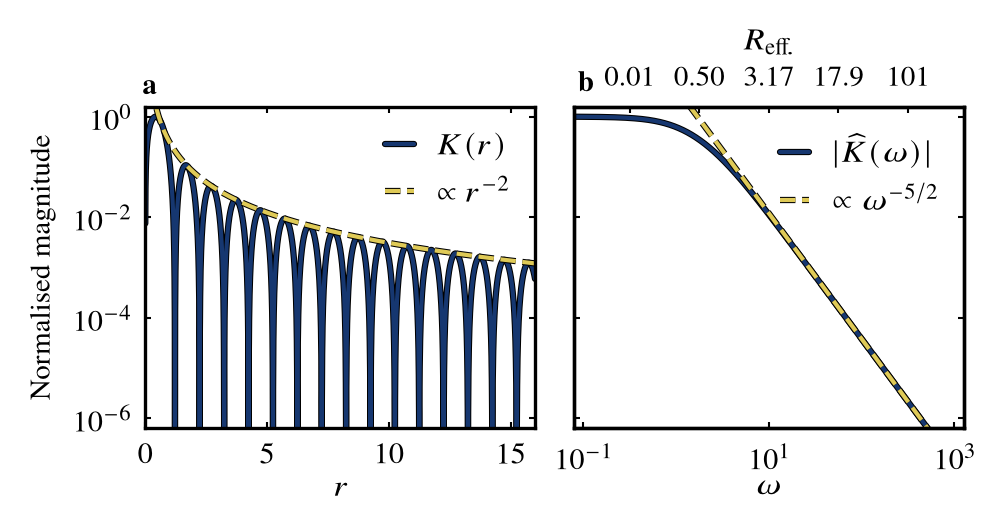

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1
import matplotlib as mpl
import matplotlib.patheffects as pe


# setting tick sizes
plt.rcParams['xtick.major.size'] = 1.5
plt.rcParams['ytick.major.size'] = 1.5

plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 0.5

plt.rcParams['xtick.minor.width'] = 0.5
plt.rcParams['ytick.minor.width'] = 0.5

plt.rcParams['xtick.minor.size'] = 1.0
plt.rcParams['ytick.minor.size'] = 1.0


fig_width_single = 82.5 / 25.4

cmap = mpl.colormaps['cividis']
color1 = cmap(0.12)
color2 = cmap(0.88)
path_effects = [
    pe.Stroke(linewidth=1.5, foreground="k"),
    pe.Normal(),
]

# ============================================================
# User controls
# ============================================================

fig_width = 5.25  # inches
D = 1.0           # use your nondimensionalised value

# left panel: linear radius range
r_max = 16.0 / D
n_r = 8000

# right panel: spectral frequency range
omega_min = 10**(-1.1)
omega_max = 10**3.1
n_omega = 1200

# shared y limits
ymin = 10**(-6.2)
ymax = 10**0.2

# whitespace / spacing
left   = 0.14
right  = 0.98
bottom = 0.16
top    = 0.82
wspace = 0.1

label_fs = 11

# ============================================================
# Helper functions
# ============================================================

def jinc(x):
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x)
    small = np.isclose(x, 0.0)
    out[small] = 0.5
    out[~small] = j1(x[~small]) / x[~small]
    return out

# Airy PSF profile:
# g(r) = pi D^2 jinc^2(pi D r)
def g_airy(r, D=1.0):
    r = np.asarray(r, dtype=float)
    x = np.pi * D * r
    return np.pi * D**2 * jinc(x)**2

# Real-space spectral convolution kernel in linear radius:
# K(r) = r g(r)
def K_r(r, D=1.0):
    r = np.asarray(r, dtype=float)
    return r * g_airy(r, D=D)

# Large-r upper envelope of K(r):
# K(r) ~ [2 / (pi^3 D)] r^{-2} cos^2(...)
# so the upper envelope is
# K_env(r) = [2 / (pi^3 D)] r^{-2}
def K_r_asymptotic_envelope(r, D=1.0):
    r = np.asarray(r, dtype=float)
    out = np.full_like(r, np.nan, dtype=float)
    mask = r > 0
    out[mask] = 2.0 / (np.pi**3 * D * r[mask]**2)
    return out

# Exact |Khat(omega)|
def Khat_abs(omega, D=1.0):
    omega = np.asarray(omega, dtype=float)
    return (
        2.0 * np.sqrt(2.0) * D / np.sqrt(np.pi)
        * np.sqrt(omega / np.tanh(np.pi * omega / 2.0))
        / ((omega**2 + 1.0) * np.sqrt(omega**2 + 9.0))
    )

# Normalised Fourier-space magnitude
def T_abs(omega, D=1.0):
    K0 = 4.0 * D / (3.0 * np.pi)
    return Khat_abs(omega, D=D) / K0

# Large-omega asymptotic of normalised |Khat|
def T_abs_asymptotic(omega):
    omega = np.asarray(omega, dtype=float)
    return (3.0 * np.sqrt(2.0 * np.pi) / 2.0) * omega**(-2.5)

# Exact mapping from omega to effective resolving power
# 2 pi / omega = log(1 + 1/R)
def R_eff_from_omega(omega):
    omega = np.asarray(omega, dtype=float)
    # return 1.0 / np.expm1(2.0 * np.pi / omega)
    return 1/(2 * np.sinh( np.pi / (2 * omega)))

def omega_from_R_eff(R):
    R = np.asarray(R, dtype=float)
    # return 2.0 * np.pi / np.log1p(1.0 / R)
    return np.pi/(2*np.asinh(1/(2 * R)))

# ============================================================
# Compute curves
# ============================================================

# Left panel
r = np.linspace(0.0, r_max, n_r)
K = K_r(r, D=D)
Kmax = np.max(K)
K_norm = K / Kmax

K_env = K_r_asymptotic_envelope(r, D=D) / Kmax

# only show the asymptotic once pi D r is safely large
mask_env = (np.pi * D * r) > 0.1

# remove exact zero from plotted y-data for log scale
K_plot = K_norm.copy()
K_plot[K_plot <= 0] = np.nan

# Right panel
omega = np.logspace(np.log10(omega_min), np.log10(omega_max), n_omega)
T = T_abs(omega, D=D)
T_asym = T_abs_asymptotic(omega)

# show Fourier asymptotic only once omega is moderately large
mask_asym = omega > 0.1

# ============================================================
# Plot
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(fig_width_single, 0.5 * fig_width_single),
    sharey=True
)

fig.subplots_adjust(
    left=left, right=right,
    bottom=bottom, top=top,
    wspace=wspace
)

# ------------------------------------------------------------
# Left: real-space kernel in linear radius
# ------------------------------------------------------------

ax1.plot(r, K_plot, label=r'$K(r)$',
         color=color1, path_effects=path_effects, solid_capstyle='round', lw=1.0)
ax1.plot(
    r[mask_env], K_env[mask_env], '--',
    label=r'$\propto r^{-2}$',
    color=color2, path_effects=path_effects, lw=1.0
)

ax1.set_yscale('log')
ax1.set_xlim(0.0, r_max)
ax1.set_ylim(ymin, ymax)

ax1.set_xlabel(r'$r$', labelpad=1.5)
ax1.set_ylabel('Normalised magnitude')
ax1.legend(frameon=False, loc='upper right', handlelength=1.0)

ax1.text(
    0.03, 1.1, r'\textbf{a}',
    transform=ax1.transAxes,
    ha='right', va='top',
)

ax1.tick_params('both',
                    direction='in',
                    right=True,
                    top=True)

# ------------------------------------------------------------
# Right: Fourier-space transfer magnitude
# ------------------------------------------------------------

ax2.plot(
    omega, T,
    label=r'$|\widehat{K}(\omega)|$',
    color=color1, path_effects=path_effects,
    solid_capstyle='round', lw=1.0,
)
ax2.plot(
    omega[mask_asym], T_asym[mask_asym], '--',
    label=r'$\propto \omega^{-5/2}$',
    color=color2, path_effects=path_effects, lw=1.0,
)

ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlim(omega_min, omega_max)
ax2.set_ylim(ymin, ymax)

ax2.set_xlabel(r'$\omega$', labelpad=-0.2)
ax2.legend(frameon=False, loc='upper right', handlelength=1.0)

ax2.text(
    0.01, 1.11, r'\textbf{b}',
    transform=ax2.transAxes,
    ha='left', va='top',
)
ax2.minorticks_off()
ax2.tick_params('both',
                    direction='in',
                    right=True)


# ------------------------------------------------------------
# Top axis on right panel: characteristic resolving power
# ------------------------------------------------------------

ax2_top = ax2.twiny()
ax2_top.set_xscale('log')
ax2_top.set_xlim(ax2.get_xlim())

R_ticks = R_eff_from_omega(np.logspace(-0.5, 2.5, 5))
#R_ticks = np.array([0.1, 1, 3, 10, 30, 100], dtype=float)
omega_ticks = omega_from_R_eff(R_ticks)

mask_ticks = (omega_ticks >= omega_min) & (omega_ticks <= omega_max)

ax2_top.set_xticks(omega_ticks[mask_ticks])
# ax2_top.set_xticklabels([f'{Rt:.3g}' for Rt in R_ticks[mask_ticks]])
ax2_top.set_xticklabels([
    f'{Rt:.2f}' if abs(Rt) < 10 else
    f'{Rt:.1f}' if abs(Rt) < 100 else
    f'{Rt:.0f}'
    for Rt in R_ticks[mask_ticks]
])
ax2_top.set_xlabel(r'$R_{\mathrm{eff}\!\mathrm{.}}$')
ax2_top.minorticks_off()
ax2_top.tick_params('both',
                    direction='in')


plt.savefig('airy_kernels_newsize.pdf', dpi=600,
            backend='pgf')
plt.show()